# 2.1 Household income distribution by planning area

Where do higher- and lower-income households live? This notebook converts Daryl's
`scripts/median_household_income_choropleth.py` (and the Excel stacked bar he built from the same
table) into the first ESDA step. It takes the SingStat table of resident households by monthly
household income band and planning area, shows the full band distribution per planning area, and
reduces it to one ordinal value per area, the **band that contains the median household**. That
median band is the planning-area income variable used downstream (subzone table in stage 1, the
income-fee regression and GWR in stage 3).

Original author: Daryl (script and Excel chart). Converted to a notebook 2026-11-10.

**Changed 2026-11-13.** Outputs moved to `output/median_household_income_planning_area/`, the default folder of
Daryl's script after his 11 Nov update (which deleted the old `resident-household-income_regression/` folder
on `main`), and the choropleth uses his fixed band colour scale (section 4). Numbers are unchanged.

**Inputs**
- `data/ResidentHouseholdsIncomebyPlanningArea.csv` (SingStat, resident households by monthly household income and planning area; 30 planning areas plus `Total` and `Others`)
- `data/MasterPlanSubZones_2019.geojson` (URA MP2019 subzones, data.gov.sg; dissolved to planning areas here)

**Outputs**
- `output/median_household_income_planning_area/planning_area_median_household_income_range.csv` (read by 1_07 in stage 1; 3_02 and 3_03 recompute the same medians from the raw table)
- `output/median_household_income_planning_area/Resident_household_income_by_planning_area.png` (100% stacked bar, report figure)
- `output/median_household_income_planning_area/median_income_choropleth.png` (median band choropleth, report figure)

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Fixed figure palette (docs/notebook_style.md): categorical order blue, orange, aqua, yellow;
# sequential = single-hue Blues; text in dark grey, never in a series colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID, SURF = "#333333", "#52514e", "#e6e5e1", "#ffffff"
plt.rcParams.update({"text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.edgecolor": GRID, "figure.facecolor": SURF,
                     "savefig.facecolor": SURF, "font.size": 9})

INCOME_CSV = DATA / "ResidentHouseholdsIncomebyPlanningArea.csv"
SUBZONES = DATA / "MasterPlanSubZones_2019.geojson"
OUT_DIR = OUT / "median_household_income_planning_area"   # Daryl's script default (main, 2026-11-11); 1_07 reads the median-band CSV from here
OUT_DIR.mkdir(parents=True, exist_ok=True)

# The 19 income bands in the order SingStat reports them (column name, label for figures).
INCOME_BANDS = [
    ("NoEmployedPerson", "No employed person"),
    ("Below_1_000", "Below $1,000"),
    ("1_000_1_999", "$1,000–$1,999"),
    ("2_000_2_999", "$2,000–$2,999"),
    ("3_000_3_999", "$3,000–$3,999"),
    ("4_000_4_999", "$4,000–$4,999"),
    ("5_000_5_999", "$5,000–$5,999"),
    ("6_000_6_999", "$6,000–$6,999"),
    ("7_000_7_999", "$7,000–$7,999"),
    ("8_000_8_999", "$8,000–$8,999"),
    ("9_000_9_999", "$9,000–$9,999"),
    ("10_000_10_999", "$10,000–$10,999"),
    ("11_000_11_999", "$11,000–$11,999"),
    ("12_000_12_999", "$12,000–$12,999"),
    ("13_000_13_999", "$13,000–$13,999"),
    ("14_000_14_999", "$14,000–$14,999"),
    ("15_000_17_499", "$15,000–$17,499"),
    ("17_500_19_999", "$17,500–$19,999"),
    ("20_000andOver", "$20,000 & over"),
]
BAND_COLS = [col for col, _ in INCOME_BANDS]
BAND_LABEL = dict(INCOME_BANDS)
# matplotlib reads "$...$" as maths, so dollar signs are escaped in figure text only.
tex = lambda label: label.replace("$", r"\$")

## 1. Load the income table

The CSV has one row per planning area plus a `Total` row and an `Others` row (areas too small to
publish separately). Both are dropped for the per-area analysis, as in Daryl's script; `Others`
is kept only in the stacked bar, where his Excel chart showed it.

In [2]:
# 1. Read the table and check that every expected band column is present.
income_raw = pd.read_csv(INCOME_CSV)
missing = [c for c in BAND_COLS if c not in income_raw.columns]
assert not missing, f"Missing income-band columns: {missing}"

# 2. Band counts must be numeric; "Total" is SingStat's own total, which differs from the band
#    sum by rounding (each cell is rounded independently), so we keep both and report the gap.
income_raw[BAND_COLS + ["Total"]] = income_raw[BAND_COLS + ["Total"]].apply(pd.to_numeric)
income_raw["Number"] = income_raw["Number"].str.strip()
income_raw["band_total"] = income_raw[BAND_COLS].sum(axis=1)

# 3. Per-area table: drop the national total and the "Others" remainder.
income = income_raw.loc[~income_raw["Number"].str.casefold().isin({"total", "others"})].copy()
income = income.sort_values("Number").reset_index(drop=True)

print(f"rows in CSV: {len(income_raw)}  ->  planning areas kept: {len(income)}")
print(f"households in kept areas: {income['Total'].sum():,}  "
      f"(national total row: {income_raw.loc[income_raw['Number'] == 'Total', 'Total'].item():,})")
print(f"largest |Total - sum of bands| per area: {(income['Total'] - income['band_total']).abs().max()}")
print(income["Number"].tolist())

rows in CSV: 32  ->  planning areas kept: 30
households in kept areas: 1,360,327  (national total row: 1,372,559)
largest |Total - sum of bands| per area: 3
['Ang Mo Kio', 'Bedok', 'Bishan', 'Bukit Batok', 'Bukit Merah', 'Bukit Panjang', 'Bukit Timah', 'Choa Chu Kang', 'Clementi', 'Downtown Core', 'Geylang', 'Hougang', 'Jurong East', 'Jurong West', 'Kallang', 'Marine Parade', 'Novena', 'Outram', 'Pasir Ris', 'Punggol', 'Queenstown', 'River Valley', 'Sembawang', 'Sengkang', 'Serangoon', 'Tampines', 'Tanglin', 'Toa Payoh', 'Woodlands', 'Yishun']


## 2. Income-band shares per planning area (100% stacked bar)

Daryl drew this chart in Excel (`Resident_household_income_by_planning_area.xlsx`, sheet
`Income Distribution`). It is redrawn here in matplotlib from the same counts so the figure is
reproducible. Bands are ordinal, so they get one sequential blue ramp (light = low income, dark =
high); households with no employed person are a separate category and are drawn in grey.

In [3]:
# 1. Shares within each area (the bar chart is 100% stacked, so areas of different size compare).
bar_table = income_raw.loc[income_raw["Number"].str.casefold() != "total"].set_index("Number")
shares = bar_table[BAND_COLS].div(bar_table[BAND_COLS].sum(axis=1), axis=0) * 100

# 2. Numbers behind the chart: where the top and bottom of the distribution sit.
top_band = shares["20_000andOver"].sort_values(ascending=False)
print("share of households at $20,000 & over, highest five:")
print(top_band.head(5).round(1).to_string())
print("\nlowest five:")
print(top_band.tail(5).round(1).to_string())
low = shares[["NoEmployedPerson", "Below_1_000", "1_000_1_999", "2_000_2_999"]].sum(axis=1)
print("\nshare with no employed person or income below $3,000, highest five:")
print(low.sort_values(ascending=False).head(5).round(1).to_string())

share of households at $20,000 & over, highest five:
Number
Tanglin          50.1
River Valley     46.8
Bukit Timah      45.5
Downtown Core    40.9
Others           30.2

lowest five:
Number
Jurong East    9.6
Sembawang      8.7
Jurong West    8.3
Yishun         7.3
Woodlands      6.4

share with no employed person or income below $3,000, highest five:
Number
Outram         48.5
Bukit Merah    37.5
Kallang        37.5
Toa Payoh      35.5
Ang Mo Kio     34.5


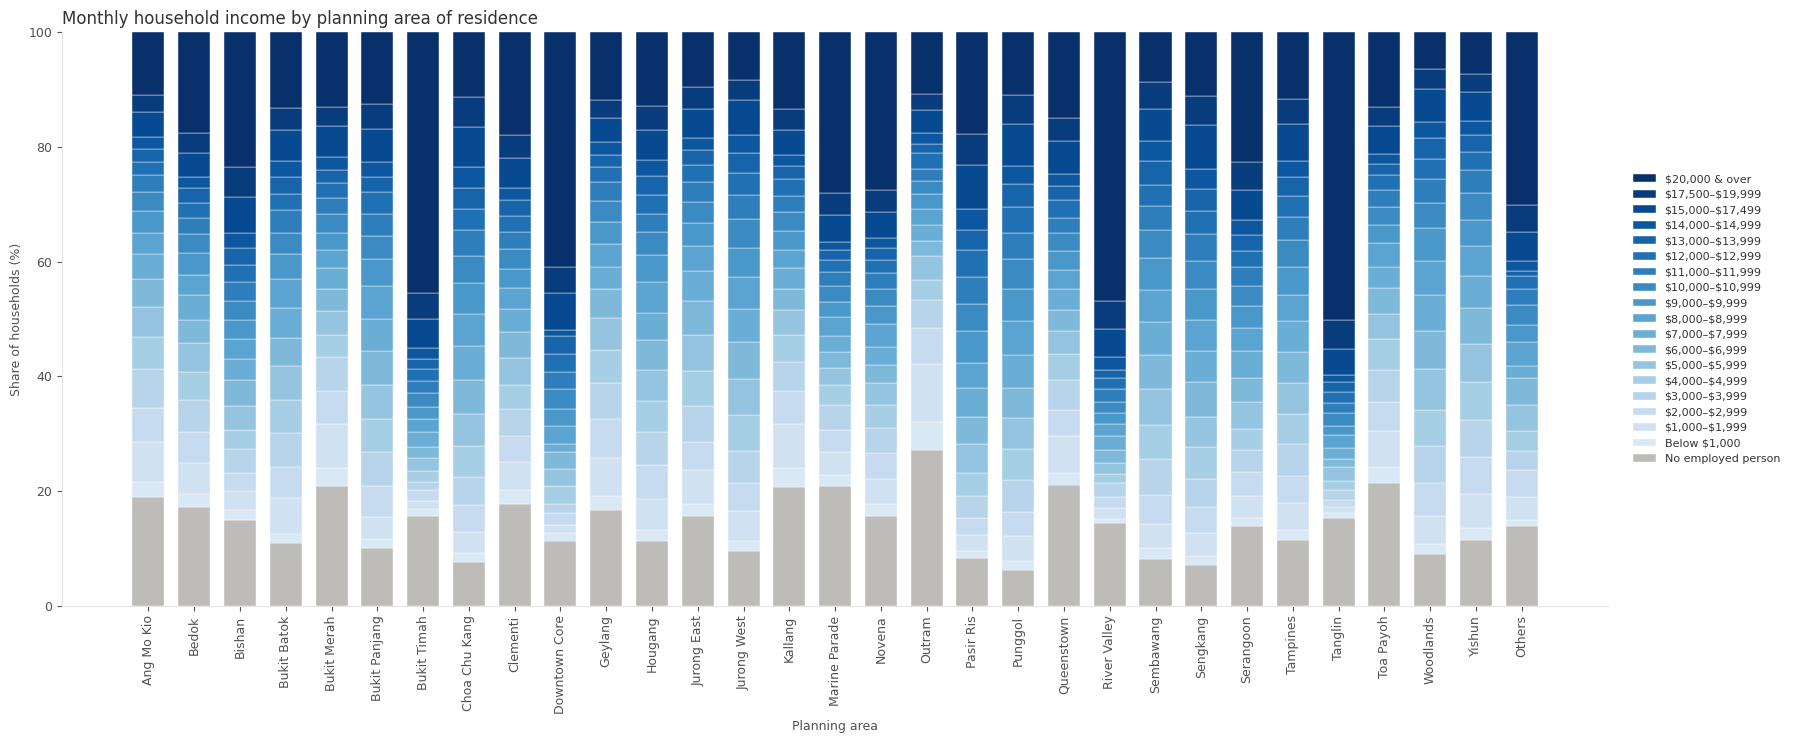

In [4]:
# 1. Colours: 18 income bands on a Blues ramp, "No employed person" in grey.
blues = plt.colormaps["Blues"]
band_colour = {"NoEmployedPerson": "#bdbcb8"}
band_colour.update({col: blues(v) for col, v in zip(BAND_COLS[1:], np.linspace(0.15, 1.0, len(BAND_COLS) - 1))})

# 2. One stacked bar per area, bands stacked bottom-up in income order.
fig, ax = plt.subplots(figsize=(18, 7.5))
bottom = np.zeros(len(shares))
for col in BAND_COLS:
    ax.bar(shares.index, shares[col], bottom=bottom, color=band_colour[col], width=0.7,
           label=tex(BAND_LABEL[col]), edgecolor="white", linewidth=0.3)
    bottom += shares[col].to_numpy()
ax.set_ylim(0, 100)
ax.set_ylabel("Share of households (%)")
ax.set_xlabel("Planning area")
ax.set_title("Monthly household income by planning area of residence", loc="left", fontsize=12)
ax.tick_params(axis="x", rotation=90)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT_DIR / "Resident_household_income_by_planning_area.png", dpi=170)
plt.show()

## 3. Median income band per planning area

Each area's household counts are cumulated across the bands in income order; the first band at
which the running total reaches half the households holds the median household. This is Daryl's
`calculate_median_ranges` unchanged. The result is ordinal (`median_income_band_order`, 0 = no
employed person ... 18 = $20,000 & over), which is why downstream work treats income as a band and
not as a dollar figure.

In [5]:
# 1. Cumulative counts along the ordered bands; the median band is the first one at or past 50%.
band_counts = income[BAND_COLS]
band_totals = band_counts.sum(axis=1)
cumulative = band_counts.cumsum(axis=1)
median_band_index = cumulative.ge(band_totals / 2, axis=0).to_numpy().argmax(axis=1)

# 2. Output table, same columns as the script so stage 1 / stage 3 readers are unchanged.
medians = pd.DataFrame({
    "planning_area": income["Number"],
    "reported_total_households": income["Total"].astype(int),
    "band_total_households": band_totals.astype(int),
    "median_income_range": [INCOME_BANDS[i][1] for i in median_band_index],
    "median_income_band_order": median_band_index,
}).sort_values("planning_area").reset_index(drop=True)

print(medians[["planning_area", "median_income_range", "median_income_band_order"]].to_string(index=False))
print("\nplanning areas per median band:")
print(medians["median_income_range"].value_counts().reindex([l for _, l in INCOME_BANDS]).dropna().astype(int).to_string())

planning_area median_income_range  median_income_band_order
   Ang Mo Kio       $5,000–$5,999                         6
        Bedok       $7,000–$7,999                         8
       Bishan     $10,000–$10,999                        11
  Bukit Batok       $7,000–$7,999                         8
  Bukit Merah       $5,000–$5,999                         6
Bukit Panjang       $8,000–$8,999                         9
  Bukit Timah     $15,000–$17,499                        16
Choa Chu Kang       $8,000–$8,999                         9
     Clementi       $7,000–$7,999                         8
Downtown Core     $15,000–$17,499                        16
      Geylang       $5,000–$5,999                         6
      Hougang       $7,000–$7,999                         8
  Jurong East       $6,000–$6,999                         7
  Jurong West       $7,000–$7,999                         8
      Kallang       $5,000–$5,999                         6
Marine Parade       $8,000–$8,999       

In [6]:
# 1. Attach the region of each planning area (from the subzone file) to see where the high bands sit.
subzones = gpd.read_file(SUBZONES)
subzones["PLN_AREA_N"] = subzones["PLN_AREA_N"].str.strip().str.upper()
region_of_area = subzones.drop_duplicates("PLN_AREA_N").set_index("PLN_AREA_N")["REGION_N"]
medians["region"] = medians["planning_area"].str.upper().map(region_of_area)
assert medians["region"].notna().all(), "every income planning area should be in the MP2019 file"

# 2. Median band by region: the central region is where the $10,000+ medians cluster.
print("median band order by region (mean over planning areas):")
print(medians.groupby("region")["median_income_band_order"].agg(["count", "mean", "min", "max"]).round(1).to_string())
high = medians.loc[medians["median_income_band_order"] >= BAND_COLS.index("10_000_10_999")]
print(f"\nareas whose median band is $10,000 or above: {len(high)}")
print(high[["planning_area", "region", "median_income_range"]].to_string(index=False))
low = medians.nsmallest(5, "median_income_band_order")
print("\nlowest five median bands:")
print(low[["planning_area", "region", "median_income_range"]].to_string(index=False))

median band order by region (mean over planning areas):
                   count  mean  min  max
region                                  
CENTRAL REGION        13  10.2    4   18
EAST REGION            3   9.3    8   11
NORTH REGION           3   8.0    7    9
NORTH-EAST REGION      5   8.8    6   10
WEST REGION            6   8.2    7    9

areas whose median band is $10,000 or above: 6
planning_area         region median_income_range
       Bishan CENTRAL REGION     $10,000–$10,999
  Bukit Timah CENTRAL REGION     $15,000–$17,499
Downtown Core CENTRAL REGION     $15,000–$17,499
    Pasir Ris    EAST REGION     $10,000–$10,999
 River Valley CENTRAL REGION     $17,500–$19,999
      Tanglin CENTRAL REGION      $20,000 & over

lowest five median bands:
planning_area            region median_income_range
       Outram    CENTRAL REGION       $3,000–$3,999
   Ang Mo Kio NORTH-EAST REGION       $5,000–$5,999
  Bukit Merah    CENTRAL REGION       $5,000–$5,999
      Geylang    CENTRAL REGION

## 4. Choropleth of the median income band

Subzones are dissolved to planning areas and each area is filled by its median band on one Blues
ramp (Daryl's colour rule: a fixed scale over all 18 income bands, shifted three bands lighter so the
lowest band present takes the lightest shade; the lighter the blue, the lower the median band; areas without an
income row, e.g. the islands and industrial areas, in light grey). Drawing is done with geopandas
instead of the script's hand-built `PatchCollection`; classes, colours and legend are the same.

planning-area polygons: 55; with income data: 30


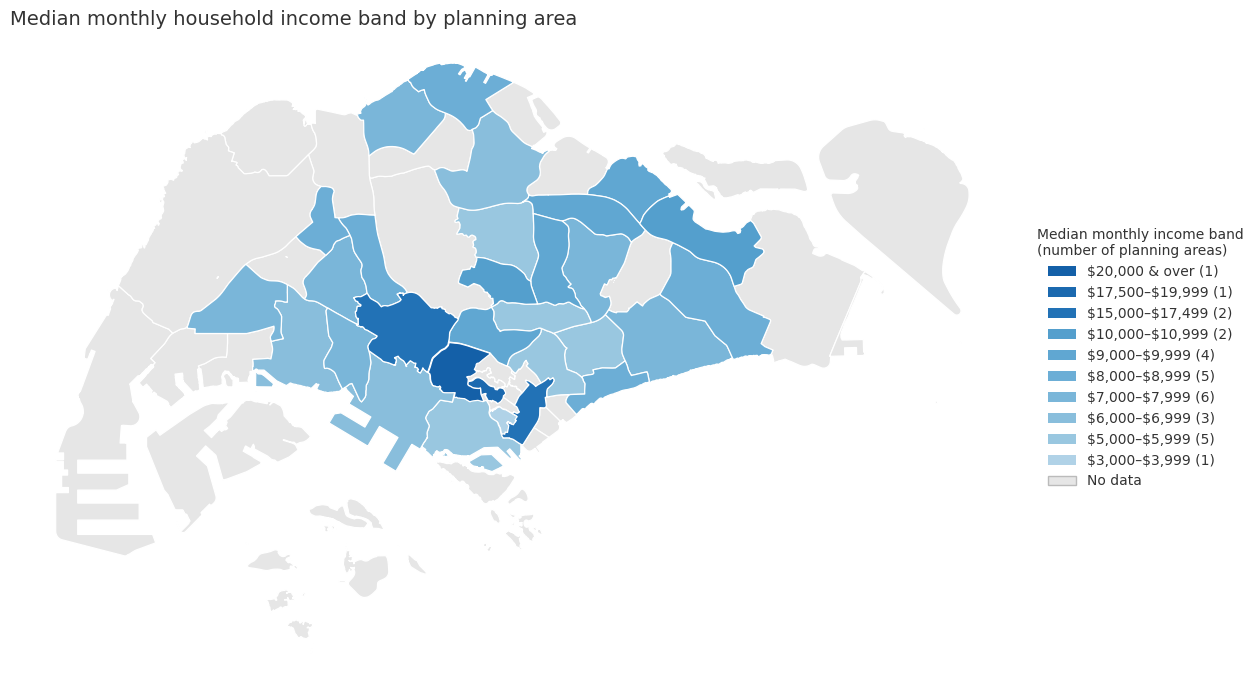

In [7]:
# 1. Dissolve subzones to planning areas and attach the median band.
# changed 2026-11-10: geopandas dissolve replaces the script's manual polygon/segment assembly;
# same classification as scripts/median_household_income_choropleth.py; colour rule below follows its 11 Nov version.
areas = subzones.dissolve(by="PLN_AREA_N", as_index=False)[["PLN_AREA_N", "geometry"]]
areas = areas.merge(medians.assign(PLN_AREA_N=medians["planning_area"].str.upper())
                    [["PLN_AREA_N", "median_income_range", "median_income_band_order"]],
                    on="PLN_AREA_N", how="left")
unmatched = sorted(set(medians["planning_area"].str.upper()) - set(areas["PLN_AREA_N"]))
assert not unmatched, f"Income planning areas missing from boundary file: {unmatched}"
print(f"planning-area polygons: {len(areas)}; with income data: {areas['median_income_range'].notna().sum()}")

# 2. Fixed band scale (changed 2026-11-13, from Daryl's 11 Nov script update): the Blues ramp (0.32-0.92) is
#    spread over all 18 numeric bands rather than only the bands present, so the shade of a band does not
#    change when the data change. Every displayed band is then shifted three bands lighter, so the lowest
#    median band in the data ($3,000-$3,999) takes the "below $1,000" shade and the darkest blues stay usable.
band_order = {label: i for i, (_, label) in enumerate(INCOME_BANDS)}
used_ranges = sorted(areas["median_income_range"].dropna().unique(), key=band_order.get)
numeric_bands = [label for col, label in INCOME_BANDS if col != "NoEmployedPerson"]
base_values = np.linspace(0.32, 0.92, len(numeric_bands))
band_index = {label: i for i, label in enumerate(numeric_bands)}
SHADE_OFFSET = 3
colour_by_range = {label: blues(base_values[max(0, band_index[label] - SHADE_OFFSET)]) for label in used_ranges}
no_data_colour = "#E6E6E6"
counts = areas["median_income_range"].value_counts()

# 3. Draw: one call per class so the legend carries the class count; white planning-area outlines.
fig, ax = plt.subplots(figsize=(13, 7))
areas[areas["median_income_range"].isna()].plot(ax=ax, color=no_data_colour, edgecolor="white", linewidth=0.9)
for label in used_ranges:
    areas[areas["median_income_range"] == label].plot(ax=ax, color=colour_by_range[label],
                                                     edgecolor="white", linewidth=0.9)
handles = [Patch(facecolor=colour_by_range[l], label=f"{tex(l)} ({counts[l]})") for l in reversed(used_ranges)]
handles.append(Patch(facecolor=no_data_colour, edgecolor="#BBBBBB", label="No data"))
ax.legend(handles=handles, title="Median monthly income band\n(number of planning areas)",
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=10, title_fontsize=10)
ax.set_title("Median monthly household income band by planning area", loc="left", fontsize=14)
ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT_DIR / "median_income_choropleth.png", dpi=240, bbox_inches="tight")
plt.show()

## 5. Write the median table

Same path and columns as the script, so `build_subzone_stats.py` (stage 1) and the stage 3
income-fee regression keep working.

In [8]:
out_csv = OUT_DIR / "planning_area_median_household_income_range.csv"
medians.drop(columns="region").to_csv(out_csv, index=False)
print(f"wrote {out_csv.relative_to(ROOT)}  ({len(medians)} planning areas)")
print(f"wrote {(OUT_DIR / 'Resident_household_income_by_planning_area.png').relative_to(ROOT)}")
print(f"wrote {(OUT_DIR / 'median_income_choropleth.png').relative_to(ROOT)}")

wrote output/median_household_income_planning_area/planning_area_median_household_income_range.csv  (30 planning areas)
wrote output/median_household_income_planning_area/Resident_household_income_by_planning_area.png
wrote output/median_household_income_planning_area/median_income_choropleth.png
